In [ ]:
"""Task 1"""

import requests
import pandas as pd
import matplotlib.pyplot as plt

with open("ID.txt") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, '')
)

json_data = response.json()

if response.status_code == 200:
    data = json_data['data']

    print('Data retrieved from frost.met.no!')

    rows = []

    for item in data:
        row = pd.DataFrame(item['observations'])
        row['referenceTime'] = item['referenceTime']
        row['sourceId'] = item['sourceId']
        rows.append(row)

    df = pd.concat(rows, ignore_index=True)

    # The original data contains multiple time offsets, we keep only one daily time offset
    df = df[df['timeOffset'] == 'PT0H'].copy()

    # Convert timestamps so they can be sorted and plotted as dates
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])

    # Sort chronologically
    df = df.sort_values('referenceTime')

    # Define x and y values
    xpoints = df['referenceTime']
    ypoints = df['value']

    plt.plot(xpoints, ypoints, marker='.', markersize=2)

    plt.xlabel('Date')
    plt.ylabel('Mean air temperature (°C)')
    plt.title('Daily mean temperature at SN17850 - 2025')
    
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

    mean_temp = df['value'].mean()
    median_temp = df['value'].median()
    min_temp = df['value'].min()
    max_temp = df['value'].max()

    summary = pd.DataFrame({
        'Statistic': ['Mean', 'Median', 'Min', 'Max'],
        'Temperature (°C)': [mean_temp.round(2),
        median_temp.round(2),
        min_temp.round(2),
        max_temp.round(2)]
    })

    print(summary.to_string(index=False))

else:
    print(f'Error! Returned status code {response.status_code}')
    print(f"Message: {json_data['error']['message']}")
    print(f"Reason: {json_data['error']['reason']}")

ModuleNotFoundError: No module named 'requests'

In [ ]:
"""Task 2"""

import requests
import pandas as pd
import matplotlib.pyplot as plt

with open("ID.txt") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

r = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, '')
)

json_data = r.json()

if r.status_code == 200:
    data = json_data['data']

    print('Data retrieved from frost.met.no!')

    rows = []

    for item in data:
        row = pd.DataFrame(item['observations'])
        row['referenceTime'] = item['referenceTime']
        row['sourceId'] = item['sourceId']
        rows.append(row)

    df = pd.concat(rows, ignore_index=True)

    # Keep only one daily time offset
    df = df[df['timeOffset'] == 'PT0H'].copy()

    # Convert Frost timestamp to datetime
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])

    # Sort chronologically
    df = df.sort_values('referenceTime')

    print(df)

    # Define x and y values
    xpoints = df['referenceTime']
    ypoints = df['value']

    # Plot
    plt.plot(xpoints, ypoints)

    plt.xlabel('Date')
    plt.ylabel('Mean air temperature (°C)')
    plt.title('Daily mean temperature at SN17850 - 2025')

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

else:
    print(f'Error! Returned status code {r.status_code}')
    print(f"Message: {json_data['error']['message']}")
    print(f"Reason: {json_data['error']['reason']}")


parameters_prec = {
    'sources': 'SN17850',
    'elements': 'sum(precipitation_amount P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

response_prec = requests.get(
    endpoint,
    params=parameters_prec,
    auth=(client_id, '')
)

json_prec = response_prec.json()

if response_prec.status_code == 200:
    rows = []
    for item in json_prec['data']:
        obs = pd.DataFrame(item['observations'])
        obs['referenceTime'] = item['referenceTime']
        rows.append(obs)

    df_prec = pd.concat(rows, ignore_index=True)

    df_prec['referenceTime'] = pd.to_datetime(df_prec['referenceTime'])
    df_prec = df_prec.sort_values('referenceTime').drop_duplicates('referenceTime')

    fig, ax1 = plt.subplots(figsize=(12, 6))

    ax1.bar(df_prec['referenceTime'], df_prec['value'],
            color='tab:blue', alpha=0.6, width=1.0, label='Nedbør (mm)')
    ax1.set_xlabel('Dato')
    ax1.set_ylabel('Nedbør (mm)', color='tab:blue')
    ax1.tick_params(axis='y', labelcolor='tab:blue')

    ax2 = ax1.twinx()
    ax2.plot(df['referenceTime'], df['value'],
             color='tab:red', linewidth=1.5, label='Temperatur (°C)')
    ax2.set_ylabel('Temperatur (°C)', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc='upper left')

    plt.title('Døgnmiddeltemperatur og døgnnedbør i Ås, 2025')
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

else:
    print(f'Error! Returned status code {response_prec.status_code}')
    print(f"Message: {json_prec['error']['message']}")
    print(f"Reason: {json_prec['error']['reason']}")

Data retrieved from frost.met.no!


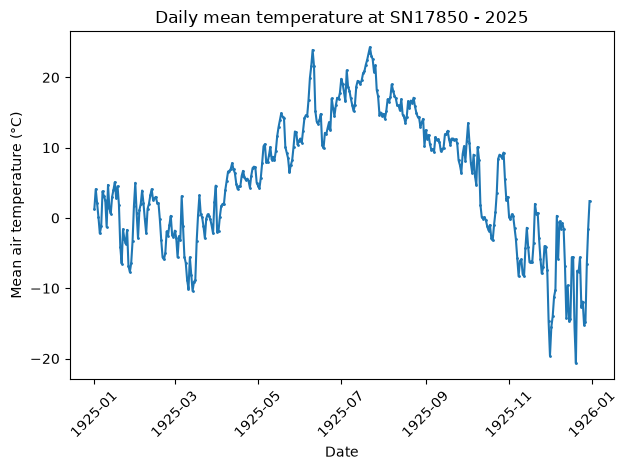

Statistic  Temperature (°C)
     Mean              5.31
   Median              5.30
      Min            -20.70
      Max             24.30


In [ ]:
"""Task 3"""

import requests
import pandas as pd
import matplotlib.pyplot as plt

with open("ID.txt") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime1': '2025-01-01/2025-12-31',
    'referencetime2': '1925-01-01/1925-12-31',
}

response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, '')
)

json_data = response.json()

if response.status_code == 200:
    data = json_data['data']

    print('Data retrieved from frost.met.no!')

    rows = []

    for item in data:
        row = pd.DataFrame(item['observations'])
        row['referencetime1'] = item['referencetime1']
        row['sourceId'] = item['sourceId']
        rows.append(row)

    df = pd.concat(rows, ignore_index=True)

    # The original data contains multiple time offsets, we keep only one daily time offset
    df = df[df['timeOffset'] == 'PT0H'].copy()

    # Convert timestamps so they can be sorted and plotted as dates
    df['referenceTime1'] = pd.to_datetime(df['referencetime1'])

    # Sort chronologically
    df = df.sort_values('referenceTime')

    # Define x and y values
    xpoints1 = df['referenceTime1']
    ypoints1 = df['value']

    plt.plot(xpoints1, ypoints1, marker='.', markersize=2)
    


    plt.xlabel('Date')
    plt.ylabel('Mean air temperature (°C)')
    plt.title('Daily mean temperature at SN17850 - 2025')
    
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

    mean_temp = df['value'].mean()
    median_temp = df['value'].median()
    min_temp = df['value'].min()
    max_temp = df['value'].max()

    summary = pd.DataFrame({
        'Statistic': ['Mean', 'Median', 'Min', 'Max'],
        'Temperature (°C)': [mean_temp.round(2),
        median_temp.round(2),
        min_temp.round(2),
        max_temp.round(2)]
    })

    print(summary.to_string(index=False))

else:
    print(f'Error! Returned status code {response.status_code}')
    print(f"Message: {json_data['error']['message']}")
    print(f"Reason: {json_data['error']['reason']}")